---

# ***Notebook 3 – Exploratory Data Analysis & Visualization***

---

In [33]:
# Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

import warnings
warnings.filterwarnings("ignore")

In [34]:
# Load Dataset
df = pd.read_csv("cleaned_naukri_jobs.csv")

df.head()

,Role Searched,Job Title,Company,Rating,Reviews,Experience,Salary,Location,Description,Skills,...,Max Experience,Average Experience,Min Salary,Max Salary,Average Salary,Posted Days,Experience Level,Salary Category,Skill Count,Primary Location
0,Data Analyst,Climate Data Analyst,MSCI Services,3.6,392.0,0-4 Yrs,Not Disclosed,Pune,The Climate Data and Content team is responsib...,"data operations, data analysis, data analysis,...",...,4.0,2.0,NaN,NaN,NaN,21.0,Entry,NaN,8.0,Pune
1,Data Analyst,Data Analyst,Snapdeal,3.6,673.0,1-6 Yrs,Not Disclosed,Gurugram,Providing technical expertise in data storage ...,"master data, python, metadata, data analysis, ...",...,6.0,3.5,NaN,NaN,NaN,21.0,Junior,NaN,8.0,Gurugram
2,Data Analyst,Data Analyst,Cognizant,3.7,63144.0,5-10 Yrs,Not Disclosed,Hyderabad,Role: Data AnalystExperience: 5+ years Preferr...,"data analysis, data visualization, advanced ex...",...,10.0,7.5,NaN,NaN,NaN,7.0,Mid,NaN,8.0,Hyderabad
3,Data Analyst,Data Analyst,MNC,NaN,NaN,0-2 Yrs,2.25-3.5 Lacs PA,"Pimpri-Chinchwad, Pune",We are looking for a motivated and detail-orie...,"google sheets, power bi, ms office, data analy...",...,2.0,1.0,2.25,3.5,2.875,2.0,Entry,Low,8.0,Pimpri-Chinchwad
4,Data Analyst,Data Analyst (English Required),Peroptyx,3.2,17.0,0-5 Yrs,Not Disclosed,Remote,"For thousands of years, maps have provided hum...","data analysis, english, data analysis, data ma...",...,5.0,2.5,NaN,NaN,NaN,14.0,Junior,NaN,8.0,Remote


In [35]:
# Basic Info
print("="*60)
print("Dataset Shape")
print("="*60)

print(df.shape)

print("\nColumns\n")
print(df.columns.tolist())

print("\nDataset Information\n")

df.info()

Dataset Shape
(4136, 23)

Columns

['Role Searched', 'Job Title', 'Company', 'Rating', 'Reviews', 'Experience', 'Salary', 'Location', 'Description', 'Skills', 'Posted', 'Job Link', 'Min Experience', 'Max Experience', 'Average Experience', 'Min Salary', 'Max Salary', 'Average Salary', 'Posted Days', 'Experience Level', 'Salary Category', 'Skill Count', 'Primary Location']

Dataset Information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4136 entries, 0 to 4135
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Role Searched       4136 non-null   object 
 1   Job Title           4136 non-null   object 
 2   Company             4136 non-null   object 
 3   Rating              3177 non-null   float64
 4   Reviews             3177 non-null   float64
 5   Experience          4084 non-null   object 
 6   Salary              4136 non-null   object 
 7   Location            4114 non-null   object 
 8   De

In [36]:
# Statistical Summary
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Role Searched,4136,6,Data Scientist,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job Title,4136,1093,Data Scientist,776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company,4136,1762,Accenture,328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,3177.0,NaN,NaN,NaN,3.610765,0.578588,1.0,3.3,3.7,3.9,5.0
Reviews,3177.0,NaN,NaN,NaN,15966.95971,31884.986184,2.0,32.0,395.0,5598.0,117626.0
Experience,4084,118,5-10 Yrs,437,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,4136,190,Not Disclosed,3639,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,4114,382,Bengaluru,1085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,4106,3001,Minimum 5 year(s) of experience is required. E...,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Skills,4103,3289,"data scientist, algorithms, python, sas, power...",17,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# Missing Values
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": round(df.isnull().mean()*100,2)
})

missing.sort_values(
    "Percentage",
    ascending=False
)

,Missing Values,Percentage
Max Salary,3673,88.81
Salary Category,3673,88.81
Average Salary,3673,88.81
Min Salary,3666,88.64
Rating,959,23.19
Reviews,959,23.19
Max Experience,58,1.40
Experience Level,58,1.40
Average Experience,58,1.40
Experience,52,1.26


### Job Market Overview

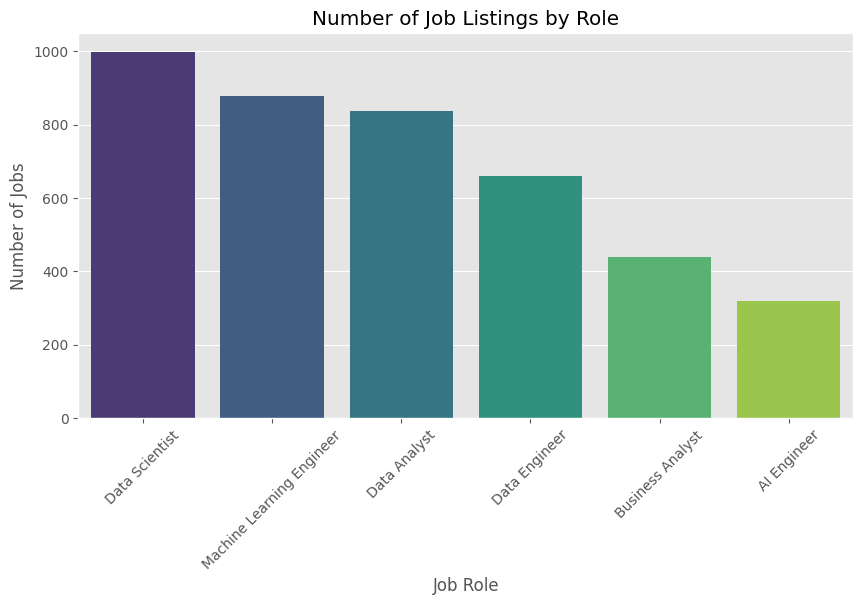

In [38]:
# Jobs By Role
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    x="Role Searched",
    order=df["Role Searched"].value_counts().index,
    palette="viridis"
)

plt.title("Number of Job Listings by Role")
plt.xlabel("Job Role")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.show()

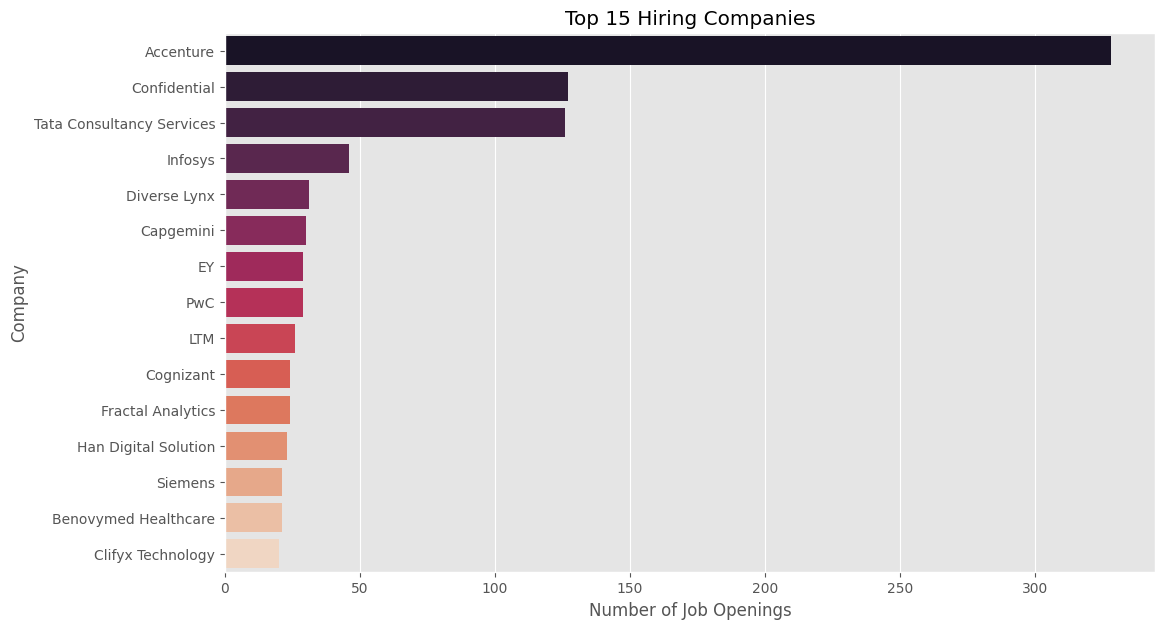

In [39]:
# Top Hiring Companies
top_company = df["Company"].value_counts().head(15)
plt.figure(figsize=(12,7))
sns.barplot(
    x=top_company.values,
    y=top_company.index,
    palette="rocket"
)

plt.title("Top 15 Hiring Companies")
plt.xlabel("Number of Job Openings")
plt.ylabel("Company")
plt.show()

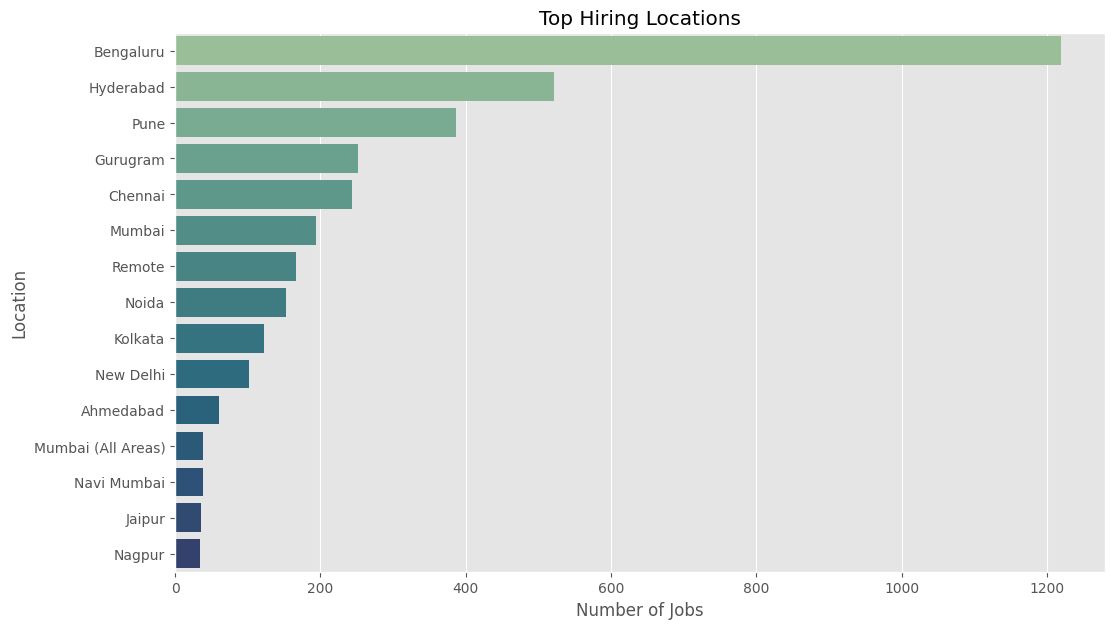

In [40]:
# Top Hiring Cities
top_city = df["Primary Location"].value_counts().head(15)
plt.figure(figsize=(12,7))
sns.barplot(
    x=top_city.values,
    y=top_city.index,
    palette="crest"
)

plt.title("Top Hiring Locations")
plt.xlabel("Number of Jobs")
plt.ylabel("Location")
plt.show()

### Experience Analysis

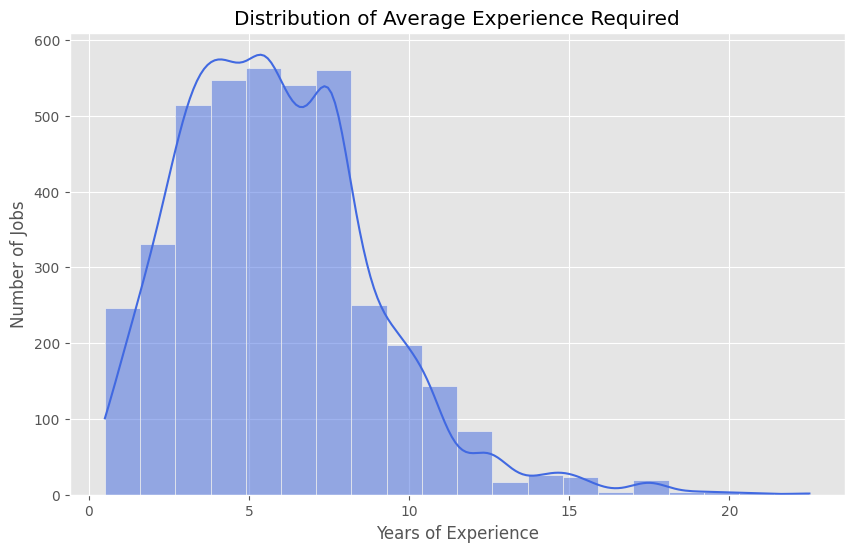

In [41]:
# Experience Distribution
plt.figure(figsize=(10,6))
sns.histplot(
    df["Average Experience"],
    bins=20,
    kde=True,
    color="royalblue"
)

plt.title("Distribution of Average Experience Required")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Jobs")
plt.show()

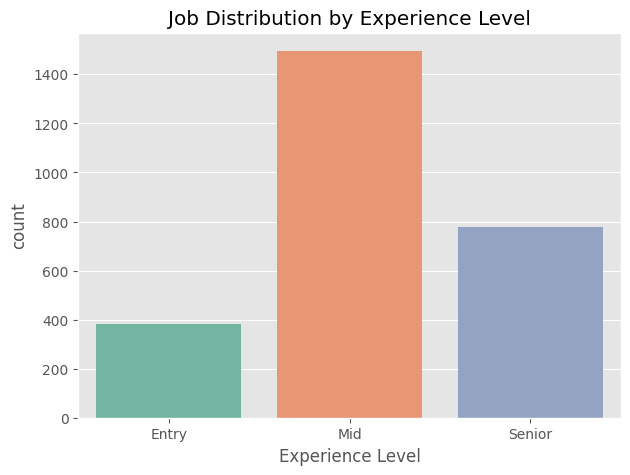

In [42]:
# Experience Level
plt.figure(figsize=(7,5))
sns.countplot(
    data=df,
    x="Experience Level",
    order=["Entry","Mid","Senior"],
    palette="Set2"
)
plt.title("Job Distribution by Experience Level")
plt.show()

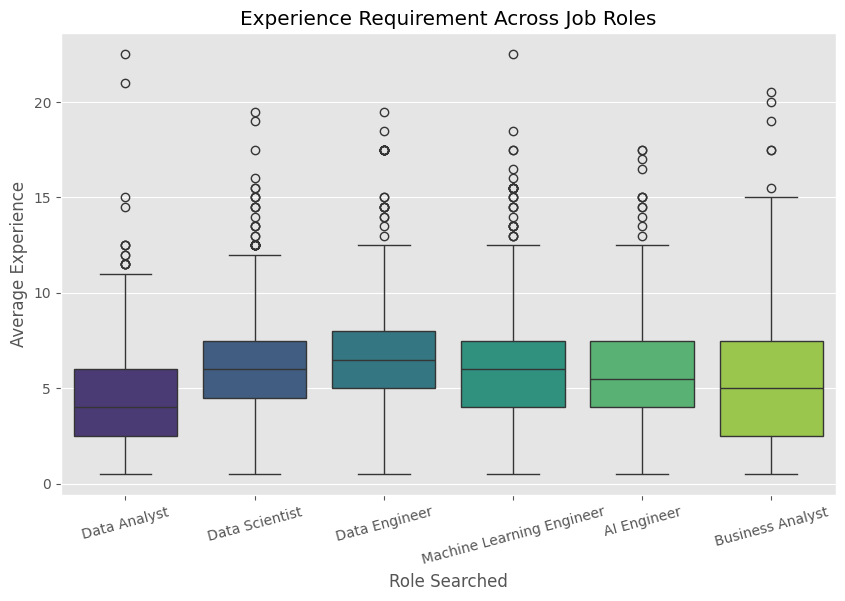

In [43]:
# Role vs Experience 
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x="Role Searched",
    y="Average Experience",
    palette="viridis"
)

plt.xticks(rotation=15)
plt.title("Experience Requirement Across Job Roles")
plt.show()

### Skills Analysis

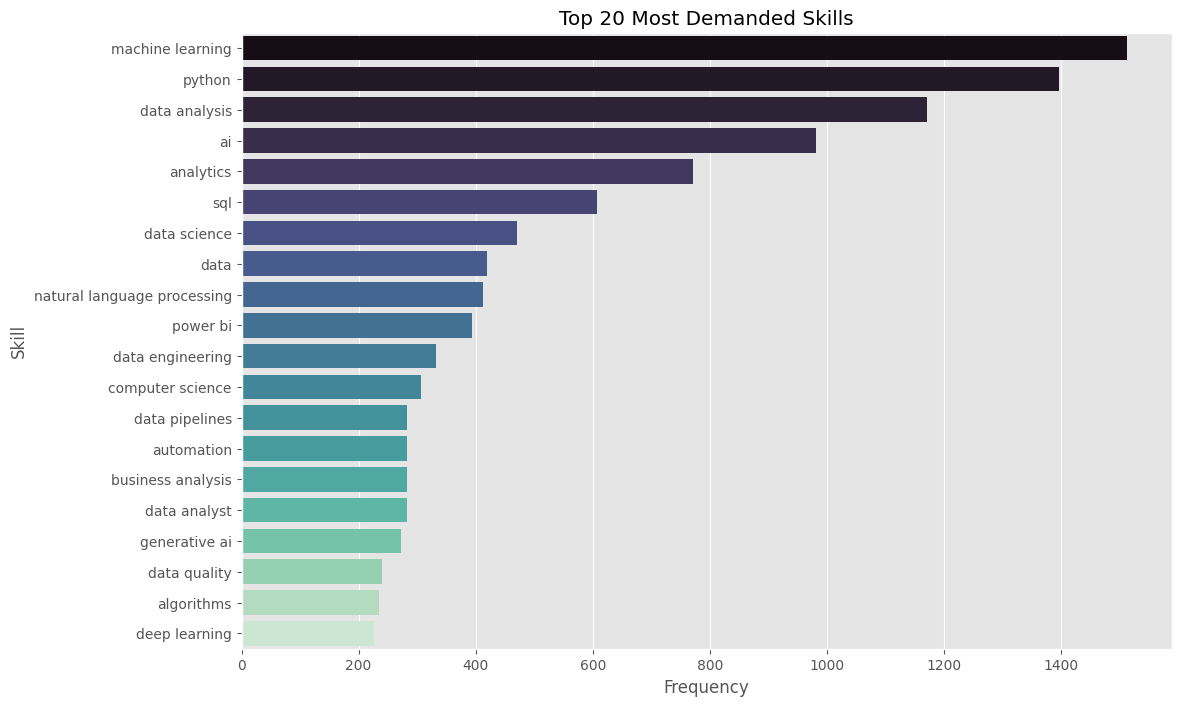

In [44]:
# Top Skills
skills = (
    df["Skills"]
      .dropna()
      .str.split(",")
      .explode()
      .str.strip()
)

top_skills = skills.value_counts().head(20)
plt.figure(figsize=(12,8))
sns.barplot(
    x=top_skills.values,
    y=top_skills.index,
    palette="mako"
)

plt.title("Top 20 Most Demanded Skills")
plt.xlabel("Frequency")
plt.ylabel("Skill")
plt.show()

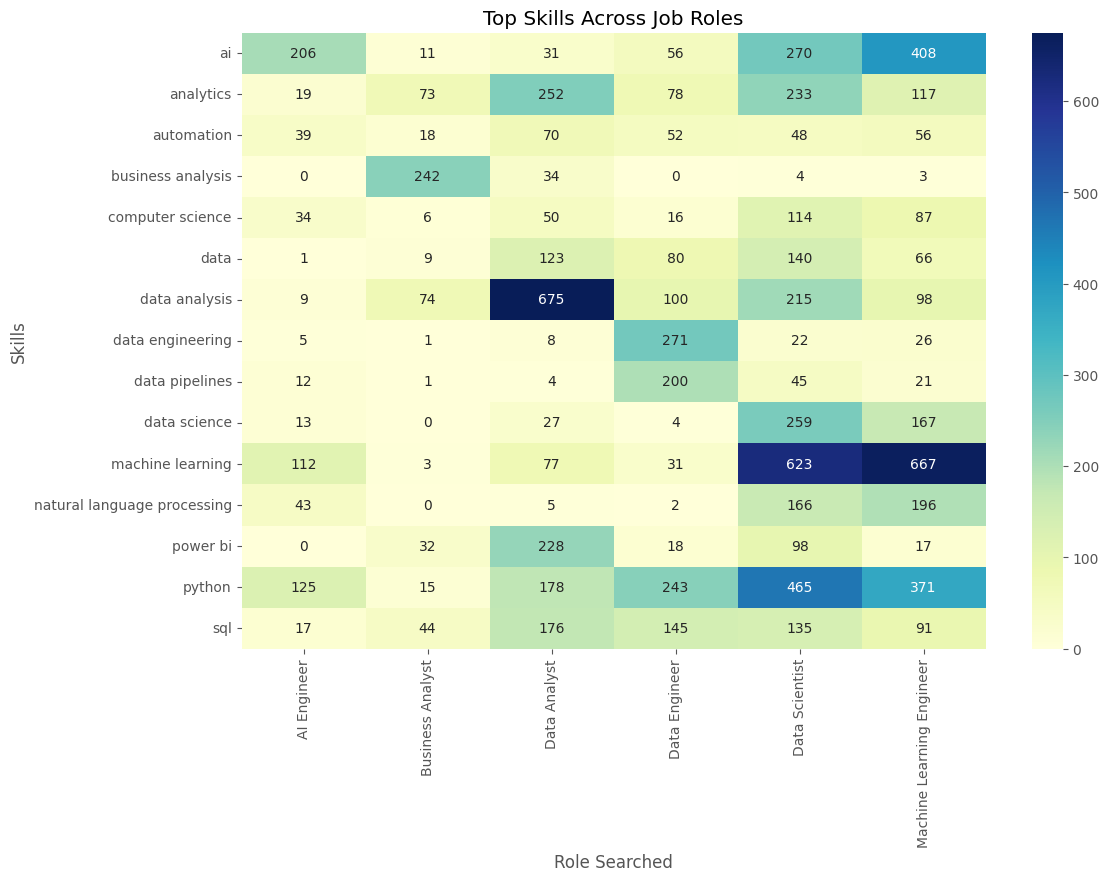

In [57]:
# Top Skills By Role
skills_role = (
    skills_df.groupby(["Role Searched","Skills"])
             .size()
             .reset_index(name="Count")
)

top_skills = (
    skills_role.groupby("Skills")["Count"]
               .sum()
               .nlargest(15)
               .index
)

pivot = (
    skills_role[skills_role["Skills"].isin(top_skills)]
    .pivot(index="Skills",
           columns="Role Searched",
           values="Count")
    .fillna(0)
)

plt.figure(figsize=(12,8))

sns.heatmap(
    pivot,
    annot=True,
    cmap="YlGnBu",
    fmt=".0f"
)

plt.title("Top Skills Across Job Roles")

plt.show()

### Company Analysis

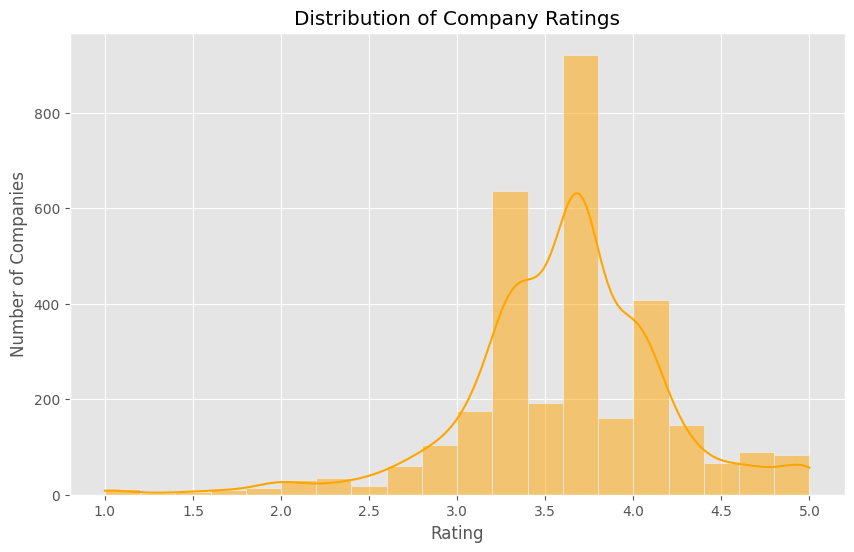

In [45]:
# Rating Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    df["Rating"],
    bins=20,
    kde=True,
    color="orange"
)

plt.title("Distribution of Company Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Companies")
plt.show()

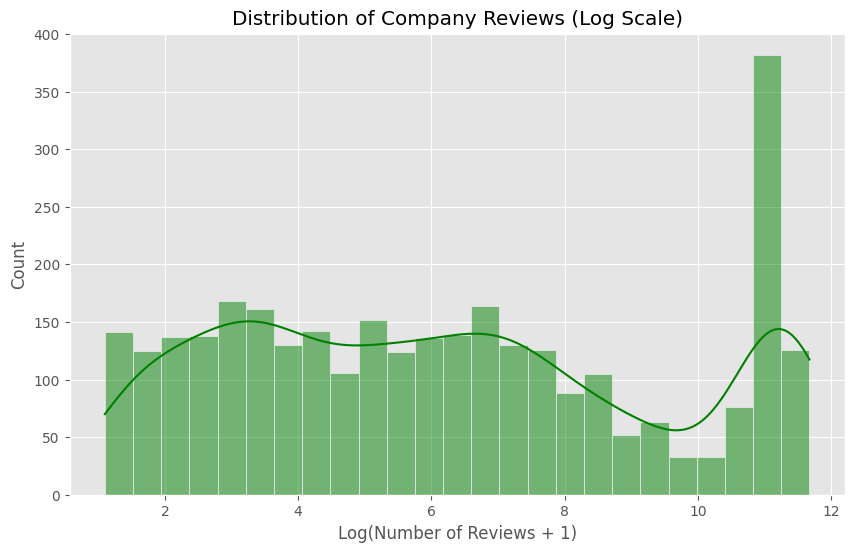

In [49]:
# Review Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    np.log1p(df["Reviews"]),
    bins=25,
    kde=True,
    color="green"
)

plt.title("Distribution of Company Reviews (Log Scale)")

plt.xlabel("Log(Number of Reviews + 1)")

plt.show()

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


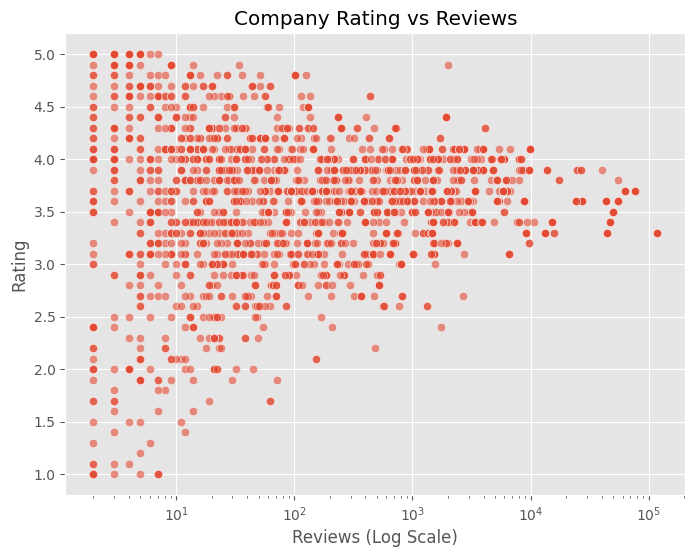

In [50]:
# Rating vs Reviews
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Reviews",
    y="Rating",
    alpha=0.6
)

plt.xscale("log")

plt.title("Company Rating vs Reviews")

plt.xlabel("Reviews (Log Scale)")

plt.ylabel("Rating")

plt.show()

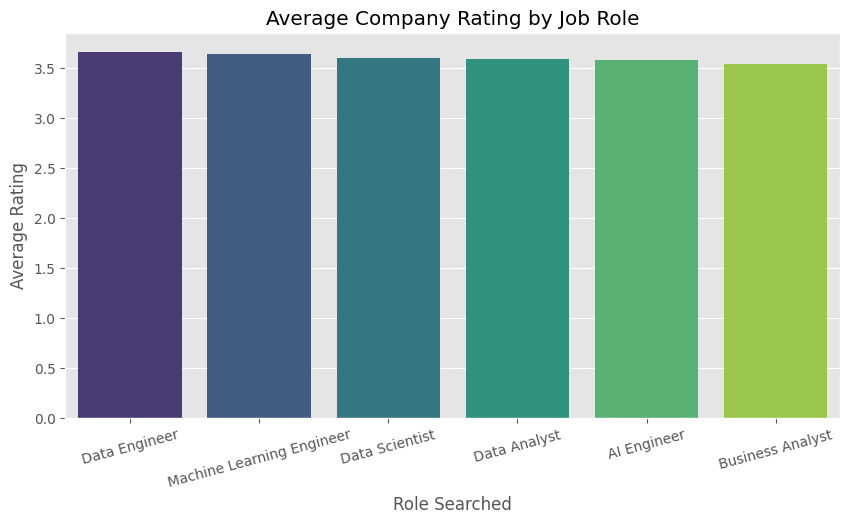

In [62]:
# Average Role By Job Role
plt.figure(figsize=(10,5))

role_rating = (
    df.groupby("Role Searched")["Rating"]
      .mean()
      .sort_values(ascending=False)
)

sns.barplot(
    x=role_rating.index,
    y=role_rating.values,
    palette="viridis"
)

plt.xticks(rotation=15)

plt.ylabel("Average Rating")

plt.title("Average Company Rating by Job Role")

plt.show()

### Jobs By Posting Age

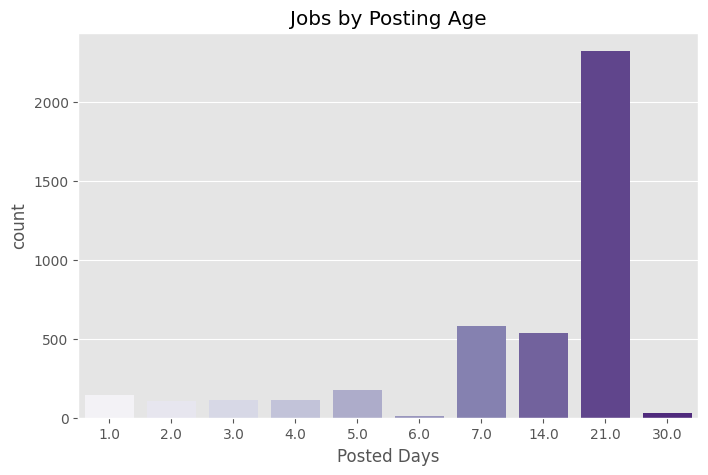

In [51]:
# Posted Days
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Posted Days",
    order=sorted(df["Posted Days"].dropna().unique()),
    palette="Purples"
)

plt.title("Jobs by Posting Age")

plt.show()

### Salary Analysis

In [60]:
# Salary vs Experience
# Remove extreme salary outliers only for visualization
Q1 = salary_df["Average Salary"].quantile(0.25)
Q3 = salary_df["Average Salary"].quantile(0.75)
IQR = Q3 - Q1

salary_plot = salary_df[
    (salary_df["Average Salary"] >= Q1 - 1.5 * IQR) &
    (salary_df["Average Salary"] <= Q3 + 1.5 * IQR)
]

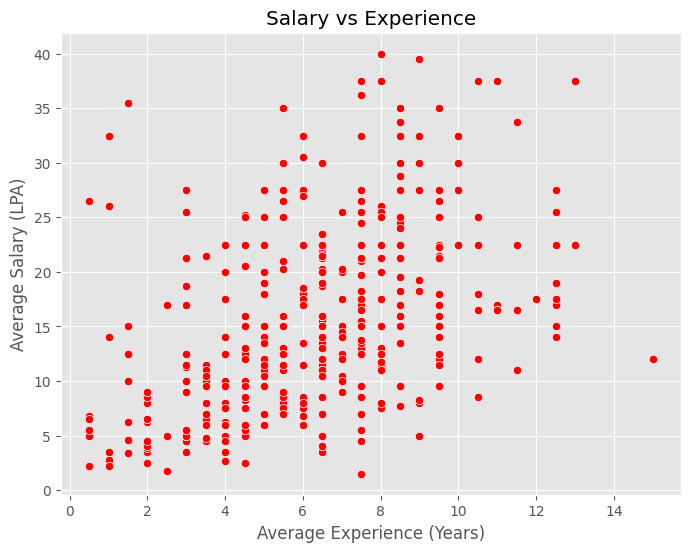

In [61]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=salary_plot,
    x="Average Experience",
    y="Average Salary",
    color="red"
)

plt.title("Salary vs Experience")

plt.xlabel("Average Experience (Years)")
plt.ylabel("Average Salary (LPA)")

plt.show()

### Correlation Analysis

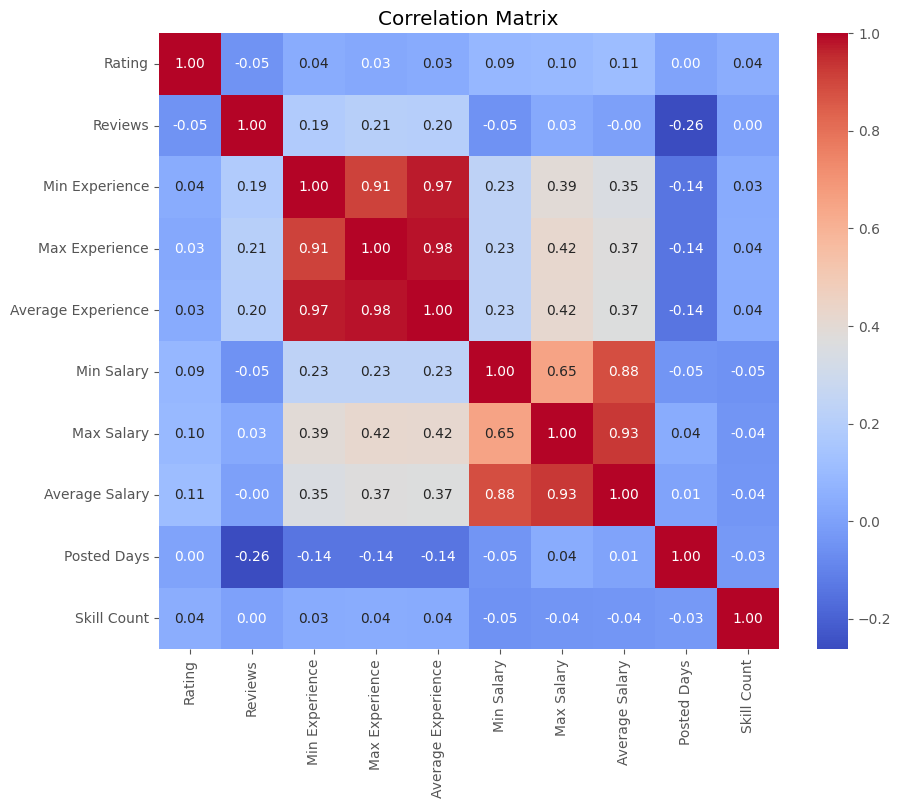

In [54]:
# Correlation Heatmap
plt.figure(figsize=(10,8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

# Key Business Insights

1. **Data Scientist** roles recorded the highest number of job postings in the collected dataset, followed closely by **Machine Learning Engineer** and **Data Analyst** roles. This indicates a strong market demand for professionals with advanced analytical and machine learning skills.

2. **Bengaluru** emerged as the leading hiring hub for data-related positions, followed by **Hyderabad** and **Pune**. These cities continue to dominate India's technology and analytics job market.

3. **Accenture** was identified as the most active recruiter in the dataset, while several other major IT consulting firms also showed significant hiring activity, highlighting the strong demand from the IT services sector.

4. Most organizations preferred candidates with **3–8 years of experience**, suggesting that employers are primarily seeking mid-level professionals with practical industry experience.

5. **Machine Learning, Python, Data Analysis, AI, SQL, and Power BI** were among the most frequently requested technical skills, reflecting the current industry requirements for data-related roles.

6. Company ratings were generally concentrated between **3.3 and 4.0**, indicating that most hiring organizations maintain above-average employee satisfaction.

7. The number of company reviews varied considerably across organizations; however, a higher number of reviews did not necessarily correspond to higher company ratings, suggesting that company popularity and employee satisfaction are not directly related.

8. A significant proportion of job postings had been active for approximately **three weeks**, indicating that many vacancies remain open for an extended period before being filled.

9. Salary information was disclosed for only a limited subset of job postings, indicating that many employers prefer not to publicly reveal compensation details. Consequently, salary-related analyses were performed only on the available records.

10. Salary generally increased with required experience, demonstrating a **moderate positive relationship** between experience and compensation. However, salary variation also depends on factors such as company, job role, location, and required skills.

11. Correlation analysis revealed that **experience-related features** showed the strongest relationship with salary, while company ratings, review counts, and skill count exhibited relatively weak relationships with salary.

12. Overall, the analysis indicates that **experience, technical skills, and geographic location** are the primary factors influencing hiring demand in India's data science and analytics job market. These findings provide valuable insights for job seekers, recruiters, and organizations seeking to understand current hiring trends.

### **Explanation**
The third notebook focused on performing Exploratory Data Analysis (EDA) to understand the current trends in the data science job market and uncover meaningful insights from the cleaned dataset. Before creating visualizations, I first examined the dataset using summary statistics and missing value analysis to understand the completeness and quality of the available information. Since a large proportion of job postings did not disclose salary details, salary-based analyses were performed only on records where salary information was available, ensuring that the visualizations accurately represented the underlying data without introducing misleading assumptions. Similarly, company ratings and reviews were analyzed only for organizations that had publicly available rating information.

To better understand hiring patterns, I created visualizations showing the distribution of job roles, top hiring companies, and major hiring locations. Experience-related analyses were performed using histograms, count plots, and boxplots to identify the most common experience requirements and compare experience expectations across different job roles. Skill analysis was carried out by extracting and standardizing individual skills from job postings, allowing the identification of the most in-demand technologies as well as the relationship between skills and specific job roles. Additional analyses examined company ratings, review distributions, job posting age, and salary trends. Correlation analysis was also performed to identify relationships among numerical features such as experience, salary, ratings, reviews, and skill count. The notebook concluded with a summary of key business insights, highlighting current hiring trends, required technical skills, geographic demand, and the factors influencing salary and employment opportunities. These findings provide a strong analytical foundation for the machine learning model and Power BI dashboard developed in the subsequent stages of the project.